In [ ]:
!pip install datasets scikit-learn

In [4]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset("preethi16102005/Jigsaw-Toxic-Comments")
print(ds)

README.md:   0%|          | 0.00/8.74k [00:00<?, ?B/s]

train.csv.gz: reconstructing file:   0%|          |  0.00B / 26.7MB            

train.csv.gz: downloading bytes:           |  0.00B            

test.csv.gz: reconstructing file:   0%|          |  0.00B / 23.7MB            

test.csv.gz: downloading bytes:           |  0.00B            

test_labels.csv.gz: reconstructing file:   0%|          |  0.00B / 1.29MB            

test_labels.csv.gz: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/159571 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/306328 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'],
        num_rows: 159571
    })
    test: Dataset({
        features: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'],
        num_rows: 306328
    })
})


In [5]:
df = ds["train"].to_pandas()
print(df.shape)
print(df.columns)
df.head()

(159571, 8)
Index(['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate'],
      dtype='object')


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405
dtype: int64
toxic            9.58
severe_toxic     1.00
obscene          5.29
threat           0.30
insult           4.94
identity_hate    0.88
dtype: float64


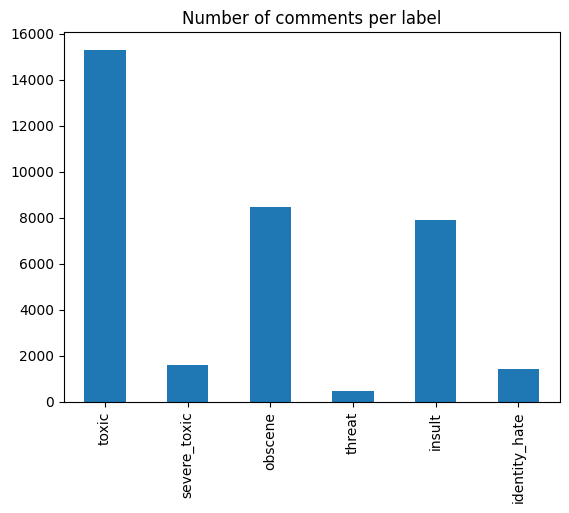

In [6]:
import matplotlib.pyplot as plt

text_col = "comment_text"
labels = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

counts = df[labels].sum()
print(counts)
print((counts / len(df) * 100).round(2))

counts.plot(kind="bar", title="Number of comments per label")
plt.show()

In [7]:
import re

def clean(text):
    text = text.lower()
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean"] = df[text_col].apply(clean)

In [8]:
for i in range(3):
    print("BEFORE:", df[text_col][i][:150])
    print("AFTER: ", df["clean"][i][:150])
    print()

BEFORE: Explanation
Why the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted
AFTER:  explanation why the edits made under my username hardcore metallica fan were reverted they weren t vandalisms just closure on some gas after i voted a

BEFORE: D'aww! He matches this background colour I'm seemingly stuck with. Thanks.  (talk) 21:51, January 11, 2016 (UTC)
AFTER:  d aww he matches this background colour i m seemingly stuck with thanks talk january utc

BEFORE: Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits instea
AFTER:  hey man i m really not trying to edit war it s just that this guy is constantly removing relevant information and talking to me through edits instead 



In [ ]:
df.to_csv("cleaned_data.csv", index=False)

In [9]:
text_col = "comment_text"
labels = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df[labels], test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(127656,) (31915,)


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words="english")
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)
print(X_train_vec.shape)

(127656, 50000)


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

model = OneVsRestClassifier(
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
model.fit(X_train_vec, y_train)

OneVsRestClassifier(estimator=LogisticRegression(class_weight='balanced',
                                                 max_iter=1000))

           label  ROC-AUC     F1  Precision  Recall
0          toxic    0.970  0.734      0.649   0.845
1   severe_toxic    0.982  0.411      0.275   0.816
2        obscene    0.985  0.781      0.705   0.876
3         threat    0.989  0.309      0.199   0.689
4         insult    0.976  0.681      0.566   0.854
5  identity_hate    0.971  0.370      0.246   0.748


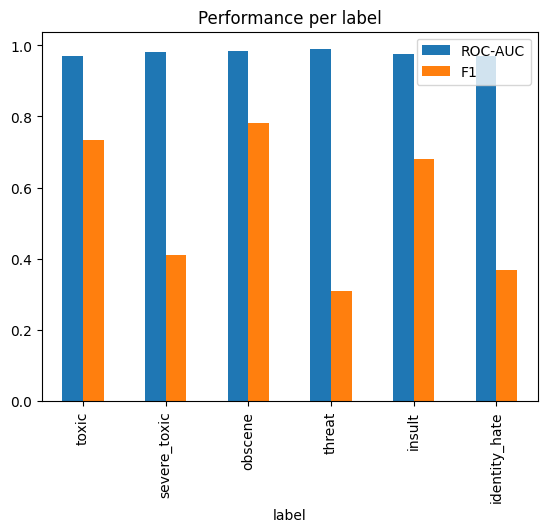

In [12]:
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score

probs = model.predict_proba(X_test_vec)
preds = (probs >= 0.5).astype(int)

rows = []
for i, lab in enumerate(labels):
    rows.append({
        "label": lab,
        "ROC-AUC": roc_auc_score(y_test[lab], probs[:, i]),
        "F1": f1_score(y_test[lab], preds[:, i]),
        "Precision": precision_score(y_test[lab], preds[:, i]),
        "Recall": recall_score(y_test[lab], preds[:, i]),
    })

results = pd.DataFrame(rows).round(3)
print(results)

results.set_index("label")[["ROC-AUC", "F1"]].plot(kind="bar", title="Performance per label")
plt.show()

In [18]:
def moderate(comment, threshold=0.5):
    vec = tfidf.transform([clean(comment)])
    p = model.predict_proba(vec)[0]
    flagged = {lab: round(float(s), 2) for lab, s in zip(labels, p) if s >= threshold}
    return flagged if flagged else "Clean comment"

   print(moderate("You are an idiot and nobody likes you"))
   print(moderate("Thanks for the good explanation!"))
   print(moderate("I will find you and hurt you"))

Clean comment


In [19]:
for t in [0.3, 0.5, 0.7]:
    preds_t = (probs >= t).astype(int)
    f1s = [round(f1_score(y_test[lab], preds_t[:, i]), 3) for i, lab in enumerate(labels)]
    prec = [round(precision_score(y_test[lab], preds_t[:, i]), 3) for i, lab in enumerate(labels)]
    rec = [round(recall_score(y_test[lab], preds_t[:, i]), 3) for i, lab in enumerate(labels)]
    print(f"Threshold {t}")
    print("  F1:       ", dict(zip(labels, f1s)))
    print("  Precision:", dict(zip(labels, prec)))
    print("  Recall:   ", dict(zip(labels, rec)))
    print()

Threshold 0.3
  F1:        {'toxic': 0.621, 'severe_toxic': 0.358, 'obscene': 0.694, 'threat': 0.223, 'insult': 0.587, 'identity_hate': 0.293}
  Precision: {'toxic': 0.467, 'severe_toxic': 0.224, 'obscene': 0.553, 'threat': 0.131, 'insult': 0.431, 'identity_hate': 0.177}
  Recall:    {'toxic': 0.928, 'severe_toxic': 0.897, 'obscene': 0.93, 'threat': 0.757, 'insult': 0.919, 'identity_hate': 0.844}

Threshold 0.5
  F1:        {'toxic': 0.734, 'severe_toxic': 0.411, 'obscene': 0.781, 'threat': 0.309, 'insult': 0.681, 'identity_hate': 0.37}
  Precision: {'toxic': 0.649, 'severe_toxic': 0.275, 'obscene': 0.705, 'threat': 0.199, 'insult': 0.566, 'identity_hate': 0.246}
  Recall:    {'toxic': 0.845, 'severe_toxic': 0.816, 'obscene': 0.876, 'threat': 0.689, 'insult': 0.854, 'identity_hate': 0.748}

Threshold 0.7
  F1:        {'toxic': 0.772, 'severe_toxic': 0.439, 'obscene': 0.803, 'threat': 0.35, 'insult': 0.714, 'identity_hate': 0.432}
  Precision: {'toxic': 0.793, 'severe_toxic': 0.313, 'ob